# DAT540 Project 3 Fatigue lifetime prediction of structural steels

Run from the `Fatigue` folder, from top to bottom. Needs `Dataset/NIMS_FATIGUE.xlsx` and the packages in `requirements.txt`.

**Group members**

- Adrian Dietrichs (Data 1, data cleaning and splitting)
- Dirhad (Data 2, models, evaluation and figures)
- *(member 3)*
- *(member 4)*
- *(member 5)*

## 1. Research question

How well can machine learning predict the fatigue life (log10 of cycles to failure) of structural steels when the model is tested on steels with material states it has never seen, and do Ridge, Random Forest and gradient boosting beat a simple Basquin baseline?

## 2. Initial data review

The dataset is the NIMS fatigue dataset with 2793 rows and 20 columns. Each row is one fatigue test on steel. The columns describe the steel grade, the heat treatment (normalizing, quenching and tempering), mechanical properties, the type of test and the stress amplitude `σa`. The target is `Nf`, the number of cycles to failure.

Several columns have missing values. Normalizing temp is missing on 71 rows, Quenching temp and Tempering temp on 336 rows, and Upper yield stress and True fracture stress on 145 rows.

`Nf` is strongly right-skewed, so we model `log10(Nf)`. Some tests were stopped without failure (run-outs). For those, `Nf` is only a lower bound.

In [1]:
import pandas as pd
raw = pd.read_excel("Dataset/NIMS_FATIGUE.xlsx")
raw.columns = raw.columns.str.strip()
print(raw.shape)
raw.info()
raw.describe().T

(2793, 20)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2793 entries, 0 to 2792
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Heat                  2793 non-null   object 
 1   Testing Material      2793 non-null   object 
 2   DS No. PDF            2793 non-null   int64  
 3   Reduction Ratio       2793 non-null   int64  
 4   dA                    2793 non-null   float64
 5   dB                    2793 non-null   float64
 6   dC                    2793 non-null   float64
 7   Normalizing temp      2722 non-null   float64
 8   Quenching temp        2457 non-null   float64
 9   Tempering temp        2457 non-null   float64
 10  Upper yield stress    2648 non-null   float64
 11  0.2% proof stress     2793 non-null   int64  
 12  Tensile strength      2793 non-null   int64  
 13  True fracture stress  2648 non-null   float64
 14  Elongation            2793 non-null   float64
 15  Reduction 

,count,mean,std,min,25%,50%,75%,max
DS No. PDF,2793.0,9.550304e+00,2.239416e+01,1.00,2.00,3.00,4.00,1.020000e+02
Reduction Ratio,2793.0,1.107362e+03,4.558772e+02,382.00,624.00,1270.00,1740.00,1.740000e+03
dA,2793.0,7.776226e-02,2.403968e-02,0.04,0.06,0.08,0.09,1.300000e-01
dB,2793.0,8.907984e-03,1.294369e-02,0.00,0.00,0.00,0.02,5.000000e-02
dC,2793.0,7.372001e-03,1.361451e-02,0.00,0.00,0.00,0.01,4.000000e-02
Normalizing temp,2722.0,8.506833e+02,1.928318e+01,825.00,825.00,845.00,865.00,8.850000e+02
Quenching temp,2457.0,8.466321e+02,1.600025e+01,825.00,825.00,845.00,865.00,8.650000e+02
Tempering temp,2457.0,5.821775e+02,9.015651e+01,180.00,550.00,600.00,650.00,6.500000e+02
Upper yield stress,2648.0,6.036310e+02,1.252465e+02,316.00,540.00,595.00,680.00,8.750000e+02
0.2% proof stress,2793.0,6.313663e+02,2.194729e+02,290.00,539.00,594.00,703.00,1.578000e+03


## 3. Cleaning, preprocessing and splitting

The code comes from `data_prep.py`. We do the following in order.

- Remove three true duplicates among the failed tests. Identical rows among run-outs are not duplicates, since they are different specimens stopped at the same limit.
- Remove 19 rows where 0.2% proof stress is higher than Tensile strength, which is physically impossible.
- Drop `DS No. PDF`, `Heat`, `Upper yield stress` and `True fracture stress`.
- Make a group ID for each material state (135 groups). Rows in the same group are very similar, so a whole group must stay on one side of a split to avoid data leakage.
- Remove run-outs (Nf of at least 1e7) from the main analysis.
- Split into train and test with `GroupShuffleSplit` (80/20) and make five grouped folds with `StratifiedGroupKFold`.
- Fill missing temperatures with the median from the training data and add flag columns.

The test set contains no S40C and only four S35C rows. Grouped cross-validation is therefore the main evaluation, and the test set is a final check.

In [2]:
import os
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold

INCLUDE_RUNOUTS = False
RUNOUT_LIMIT = 1e7
TEST_SIZE = 0.2
N_FOLDS = 5
SEED = 42

TEMP_COLS = ["Normalizing temp", "Quenching temp", "Tempering temp"]
DROP_COLS = ["DS No. PDF", "Heat", "Upper yield stress", "True fracture stress"]

steps = []

In [3]:
df = pd.read_excel("Dataset/NIMS_FATIGUE.xlsx")
df.columns = df.columns.str.strip()
steps.append(("loaded", len(df)))

# only drop duplicates among failed tests, identical run-outs are different specimens
is_duplicate = df.duplicated() & (df["Nf"] < RUNOUT_LIMIT)
df = df[~is_duplicate].reset_index(drop=True)
steps.append(("duplicates removed (failed tests only)", len(df)))

# proof stress above tensile strength can't be right
impossible = df["0.2% proof stress"] > df["Tensile strength"]
df = df[~impossible].reset_index(drop=True)
steps.append(("proof stress > tensile strength removed", len(df)))

df = df.drop(columns=DROP_COLS)

# one group = one material state, rows in a group are near copies
state_cols = [c for c in df.columns if c not in ("Nf", "σa", "Type of test")]
df["group"] = df.groupby(state_cols, dropna=False).ngroup()
steps.append((f"groups made ({df['group'].nunique()} material states)", len(df)))

In [4]:
# log10 because Nf is very skewed
df["runout"] = (df["Nf"] >= RUNOUT_LIMIT).astype(int)
df["log10_Nf"] = np.log10(df["Nf"])
df = df.drop(columns=["Nf"])

df["Type of test"] = (df["Type of test"] == "Uniaxial loading").astype(int)
df = pd.get_dummies(df, columns=["Testing Material"], prefix="mat", dtype=int)

In [5]:
# split on groups, not rows, otherwise train and test leak
splitter = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=SEED)
train_idx, test_idx = next(splitter.split(df, groups=df["group"]))
train = df.iloc[train_idx].copy()
test = df.iloc[test_idx].copy()
steps.append(("split: train rows", len(train)))
steps.append(("split: test rows", len(test)))

# run-outs only give a lower bound for Nf
if not INCLUDE_RUNOUTS:
    train = train[train["runout"] == 0].copy()
    test = test[test["runout"] == 0].copy()
steps.append(("after run-out choice: train rows", len(train)))
steps.append(("after run-out choice: test rows", len(test)))

In [6]:
# folds also keep groups together, spread over steel grades
mat_cols = [c for c in train.columns if c.startswith("mat_")]
grade = train[mat_cols].idxmax(axis=1)
cv = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
train["fold"] = -1
for k, (_, val_idx) in enumerate(cv.split(train, grade, groups=train["group"])):
    train.iloc[val_idx, train.columns.get_loc("fold")] = k
test["fold"] = -1

In [7]:
# fill missing temps with the train median, keep a flag
for col in TEMP_COLS:
    train[col + " missing"] = train[col].isna().astype(int)
    test[col + " missing"] = test[col].isna().astype(int)
    median = train[col].median()
    train[col] = train[col].fillna(median)
    test[col] = test[col].fillna(median)

# these two flags turned out identical
same_flag = "Tempering temp missing"
assert (train[same_flag] == train["Quenching temp missing"]).all()
assert (test[same_flag] == test["Quenching temp missing"]).all()
train = train.drop(columns=same_flag)
test = test.drop(columns=same_flag)

# sanity checks
assert train.isna().sum().sum() == 0 and test.isna().sum().sum() == 0, "missing values left"
assert not set(train["group"]) & set(test["group"]), "a group is in both train and test"
assert train.select_dtypes(exclude="number").empty, "non-numeric column left"
assert train.groupby("group")["fold"].nunique().max() == 1, "a group is split over folds"
assert sorted(train["fold"].unique()) == list(range(N_FOLDS)), "empty fold"

In [8]:
print("Step log (rows after each step)")
for name, n in steps:
    print(f"  {name}: {n}")
print("\nMaterial counts in train / test")
print(pd.DataFrame({"train": train[mat_cols].sum(), "test": test[mat_cols].sum()}))
print("\nRows and groups per fold")
print(train.groupby("fold").agg(rows=("group", "size"), groups=("group", "nunique")))
print(train.groupby("fold")[mat_cols].sum())
print("\nType of test (1 = uniaxial): train / test mean")
print(train["Type of test"].mean().round(3), test["Type of test"].mean().round(3))
print("\nlog10_Nf describe")
print(pd.DataFrame({"train": train["log10_Nf"].describe(), "test": test["log10_Nf"].describe()}))

os.makedirs("Data", exist_ok=True)
suffix = "_with_runouts" if INCLUDE_RUNOUTS else ""
train.to_csv(f"Data/train{suffix}.csv", index=False)
test.to_csv(f"Data/test{suffix}.csv", index=False)
print(f"\nSaved Data/train{suffix}.csv and Data/test{suffix}.csv")

Step log (rows after each step)
  loaded: 2793
  duplicates removed (failed tests only): 2790
  proof stress > tensile strength removed: 2771
  groups made (135 material states): 2771
  split: train rows: 2246
  split: test rows: 525
  after run-out choice: train rows: 1588
  after run-out choice: test rows: 372

Material counts in train / test
          train  test
mat_S25C    609   195
mat_S35C     37     4
mat_S40C     85     0
mat_S45C    444    92
mat_S55C    413    81

Rows and groups per fold
      rows  groups
fold              
0      326      22
1      295      22
2      301      22
3      323      22
4      343      20
      mat_S25C  mat_S35C  mat_S40C  mat_S45C  mat_S55C
fold                                                  
0           93         4        24        99       106
1          138        12        31        60        54
2           99        10         0        98        94
3          112         6         0       113        92
4          167         5        

## 4. Visualization of the data

Here we make three figures that show the data before modelling. The figures are saved as `figures/explore_*.png`.

- **Target distribution.** `Nf` is strongly right-skewed, and log10 makes the distribution much easier to handle. The figure also shows the run-outs, which stop at 1e7.
- **S-N curves per steel grade.** Higher stress gives shorter life, and the curves are shifted for different steel grades. Both stress and steel grade must therefore be in the model.
- **Correlations.** The strength columns (proof stress, tensile strength and Vickers hardness) are almost identical, and `σa` correlates strongly with life.

The result figures from `plot.py` are made in section 7, after the models are tuned.

In [9]:
import os
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

OUT = "figures"
MAIN = "#2a78d6"
GREY = "#8c8a84"
INK = "#3f3e3c"

def explore_save(fig, name):
    os.makedirs(OUT, exist_ok=True)
    fig.tight_layout()
    fig.savefig(f"{OUT}/{name}.png", bbox_inches="tight", dpi=150)
    plt.show()
    plt.close(fig)


In [10]:
GRADE_COLORS = {
    "S25C": "#2a78d6",
    "S35C": "#eb6834",
    "S40C": "#1baf7a",
    "S45C": "#eda100",
    "S55C": "#e87ba4",
}


def plot_target_distribution(raw):
    # Why the target is log10(Nf) and why run-outs are left out. Uses the raw Excel file.
    nf = raw["Nf"]
    runout = nf >= 1e7
    fig, (left, right) = plt.subplots(1, 2, figsize=(9, 3.5))

    left.hist(nf[~runout], bins=40, color=MAIN)
    left.set_xlabel("Cycles to failure, Nf")
    left.set_ylabel("Number of tests")
    left.set_title(f"Failed tests, raw Nf (skew {nf[~runout].skew():.1f})", loc="left", fontsize=10)

    bins = np.linspace(4, 10, 49)
    right.hist(np.log10(nf[~runout]), bins=bins, color=MAIN, label=f"Failed ({(~runout).sum()})")
    right.hist(np.log10(nf[runout]), bins=bins, color=GREY, label=f"Run-out, Nf ≥ 10⁷ ({runout.sum()})")
    right.axvline(7, color=INK, linestyle="--", linewidth=1)
    right.set_xlabel("log10(Nf)")
    right.set_title(f"All tests, log scale (skew of failed {np.log10(nf[~runout]).skew():.1f})", loc="left", fontsize=10)
    right.legend(frameon=False, fontsize=8)
    for ax in (left, right):
        ax.grid(axis="x", visible=False)
    explore_save(fig, "explore_1_target_distribution")


def plot_sn_curves(df):
    # S-N data, raw stress and stress divided by tensile strength. 
    grade = df[[f"mat_{g}" for g in GRADE_COLORS]].idxmax(axis=1).str[4:]
    ratio = df["sigma_a"] / df["Tensile strength"]
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharex=True)
    for ax, y, label in [(axes[0], df["sigma_a"], "Stress amplitude σa (MPa)"),
                         (axes[1], ratio, "σa / tensile strength")]:
        for g, color in GRADE_COLORS.items():
            rows = grade == g
            ax.scatter(10 ** df.loc[rows, "log10_Nf"], y[rows], s=10, color=color, alpha=0.7,
                       edgecolors="white", linewidths=0.4, label=f"{g} ({rows.sum()})")
        r = np.corrcoef(y, df["log10_Nf"])[0, 1]
        ax.set_title(f"{label.split(' (')[0]}, r = {r:.2f} with log10(Nf)", loc="left", fontsize=10)
        ax.set_ylabel(label)
        ax.set_xscale("log")
        ax.set_xlabel("Cycles to failure, Nf (log scale)")
    axes[1].legend(title="Grade (rows)", frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
    fig.suptitle("S-N data per steel grade (train set)", x=0.02, ha="left")
    explore_save(fig, "explore_2_sn_curves")


def plot_correlation(df):
    # Correlation between the numeric inputs and the target
    cols = ["sigma_a", "0.2% proof stress", "Tensile strength", "Vickers hardness", "Elongation",
            "Reduction of area", "Tempering temp", "Quenching temp", "Normalizing temp",
            "Reduction Ratio", "dA", "dB", "dC", "log10_Nf"]
    corr = df[cols].corr()
    corr = corr.where(np.tril(np.ones(corr.shape, dtype=bool)))
    fig, ax = plt.subplots(figsize=(7.5, 6.5))
    im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
    for i in range(len(cols)):
        for j in range(i + 1):
            v = corr.iloc[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(v) > 0.6 else INK)
    ax.set_xticks(range(len(cols)), cols, rotation=90)
    ax.set_yticks(range(len(cols)), cols)
    ax.grid(False)
    ax.spines[["left", "bottom"]].set_visible(False)
    fig.colorbar(im, ax=ax, shrink=0.7, label="Pearson r")
    ax.set_title("Correlation between features and log10(Nf) (train set)", loc="left")
    explore_save(fig, "explore_3_correlation")

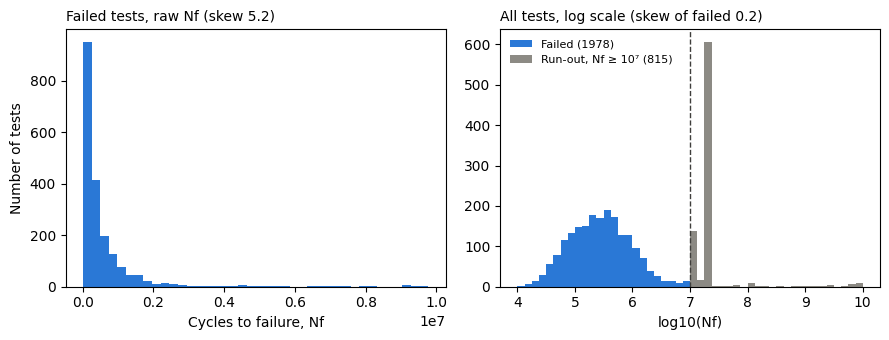

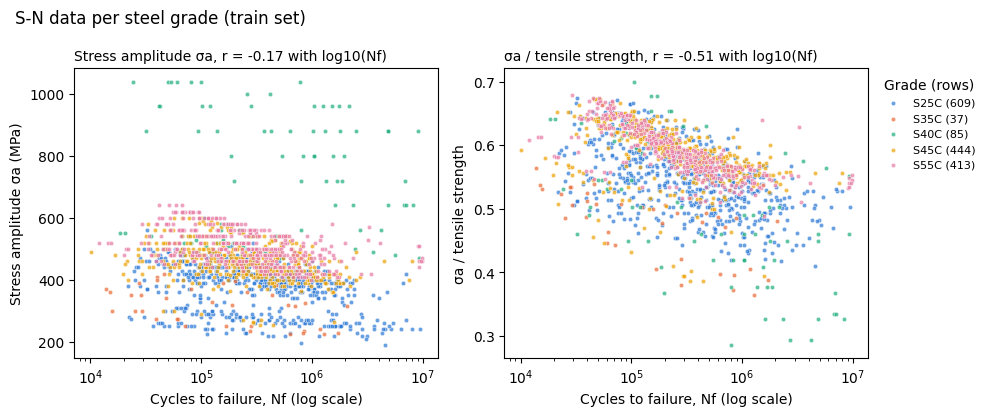

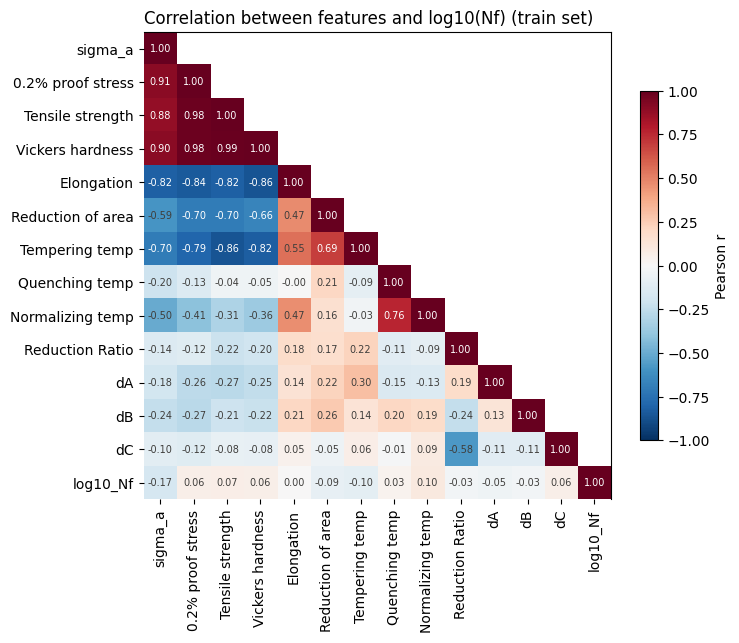

In [11]:
df = pd.read_csv("Data/train.csv").rename(columns={"σa": "sigma_a"})
plot_target_distribution(raw)
plot_sn_curves(df)
plot_correlation(df)

## 5. Models and evaluation setup

The code comes from `evaluate.py`. We compare four methods.

- **Basquin baseline.** A simple physical model where log life depends linearly on log stress. It shows what a simple model can do.
- **Ridge regression.** A linear model with a penalty on large coefficients. We need Ridge because the temperature columns are almost linear functions of the steel grades, which makes ordinary linear regression unstable.
- **Random Forest.** Many decision trees averaged together. Captures non-linear relationships and handles different scales.
- **HistGradientBoosting.** Trees built one after another, each correcting the errors of the previous ones. Often the best on tabular data of this size.

We use scikit-learn for all of them. The models are measured with RMSE, MAE, R² and the share of predictions within a factor of 2 of the true life. All models are evaluated with the same five grouped folds.

In [12]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import GroupKFold, GridSearchCV, PredefinedSplit
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
import warnings

#---------------------------------------------------------------------------------
# How many bending cycles (fatigue) before the metal fails
# Nf is the number we count up to (Number of cycles until failure)
# N for number (of cycles), f for failure, σa is how hard you bend it (MPa)
# Sigma is stress, a is amplitude

# Important terms:
# RMSE - typical miss in log units
# MAE - average miss without squaring
# R^2 - share of the variation the model explains (1 = perfect)
#---------------------------------------------------------------------------------


warnings.filterwarnings("ignore", category=UserWarning)

# Show all columns when printing tables
pd.set_option("display.width", 200) 
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_columns", None)

# Columns that are never used as inputs
DROP_FROM_X = ["log10_Nf", "group", "fold", "runout"]


COLLINEAR_BLOCKS = {
    "strength (proof/tensile/vickers)":
        ["0.2% proof stress", "Tensile strength", "Vickers hardness"],
}


TRAIN_PATH = "Data/train.csv"

# Train with: "Data/train.csv" 
# Train with runouts (run outs have censored Nf, not a real failure life): "Data/train_with_runouts.csv" 

In [13]:
def load_clean(path=TRAIN_PATH ):
    # Load Data 1's cleaned split
    df = pd.read_csv(path)
    df = df.rename(columns={"σa": "sigma_a"}) # rename to sigma_a
    X = df.drop(columns=[c for c in DROP_FROM_X if c in df.columns]) # Removes the columns from the table
    y = df["log10_Nf"] # y is what its supposed to guess
    groups = df["group"] 
    folds = df["fold"] if "fold" in df.columns else None 
    return X, y, groups, folds


def compute_metrics(y_true, y_pred):
    # 4 metrics on how wrong a prediction was 
    rmse = np.sqrt(mean_squared_error(y_true, y_pred)) # Typical miss
    mae = mean_absolute_error(y_true, y_pred) # Mean of average error
    r2 = r2_score(y_true, y_pred) # share of the variation score (1.0 is perfect, 0.0 is worst)

    s = np.abs(y_pred - y_true) # Abs misses per row
    hits = s < np.log10(2) # True where they are within a factor of 2
    within_factor_2 = np.mean(hits) # True counts as 1, so mean = share
    
    return {"rmse": rmse, "mae": mae, "r2": r2, "within_factor_2": within_factor_2}


def self_test():
    # Check so the metrics verify themselves on every run
    y_true = np.array([4.0, 5.0, 6.0])
    perfect = compute_metrics(y_true, y_true)
    assert perfect["rmse"] == 0.0 and perfect["r2"] == 1.0 # Assert crashes the program if the guess is False
    assert perfect["within_factor_2"] == 1.0
    missed = compute_metrics(y_true, np.array([4.0, 5.0, 6.31]))
    assert abs(missed["within_factor_2"] - 2 / 3) < 1e-9


def basquin_baseline(X_train, y_train, X_test):
    # Straight line between log stress and log lifetime - Basquins Law
    # Uses only sigma_a, no material information
    log_sigma_train = np.log10(X_train[["sigma_a"]]) 
    log_sigma_test = np.log10(X_test[["sigma_a"]])
    model = LinearRegression().fit(log_sigma_train, y_train)

    return model.predict(log_sigma_test)

def sklearn_fit_predict(model):
    # First fit then predict the different models
    def inner(X_train, y_train, X_test):
        return model.fit(X_train, y_train).predict(X_test)
    return inner

def cross_validate_model(fit_predict, X, y, groups, n_splits = 5):
    # Backup Cross validation, only used when there is no "fold" column
    # GroupKFold makes its own 5 splits so no material group is in both train and test

    gkf = GroupKFold(n_splits=n_splits)
    results = []
    for fold, (train_idx, test_idx) in enumerate(gkf.split(X, y, groups)):
        X_tr, X_te = X.iloc[train_idx], X.iloc[test_idx]
        y_tr, y_te = y.iloc[train_idx], y.iloc[test_idx]
        y_pred = fit_predict(X_tr, y_tr, X_te) # Train on four parts, guess fifth
        m = compute_metrics(y_te, y_pred) # Score the guess against the hidden answers
        m["fold"] = fold
        m["n_test"] = len(test_idx) # How many rows were in this test part
        results.append(m)
    return pd.DataFrame(results)

def cross_validate_folds(fit_predict, X, y, folds):
    # Five rounds. For every round one bit is test and the 4 others are training bits.
    # Uses the fixed folds from data_prep.py

    results = []
    for f in sorted(folds.unique()):
        # folds == f gives a list with True or False, one per row
        # X[te] picks out the rows with True inside
        tr, te = folds != f, folds == f  
        y_pred = fit_predict(X[tr], y[tr], X[te])

        # Train on four bits, and guess the fifth
        m = compute_metrics(y[te], y_pred)

        # Compare the guess with the correct answer which we have hidden
        m["fold"] = f
        m["n_test"] = int(te.sum())
        results.append(m)
    return pd.DataFrame(results)


def feature_importance(model, X, y, folds, n_repeats=10, seed=0):
    # Permutation importance, shuffle one column so it carries no information 
    # and measure how much worse the RMSE gets. 
    # Big increase -> the model relies on the column. 

    # Every column is its own item, except the strength columns which form one item together
    blocked = [c for cols in COLLINEAR_BLOCKS.values() for c in cols]
    items = {c: [c] for c in X.columns if c not in blocked}
    items.update(COLLINEAR_BLOCKS)

    # Fixed seed, so the shuffles are the same every run
    rng = np.random.default_rng(seed)
    scores = {name: [] for name in items}
 
    for f in sorted(folds.unique()):
        tr, te = folds != f, folds == f
        fitted = clone(model).fit(X[tr], y[tr]) 
        X_val = X[te].reset_index(drop=True)
        y_val = y[te].reset_index(drop=True)
        base = np.sqrt(np.mean((fitted.predict(X_val) - y_val) ** 2))
 
        for name, cols in items.items():
            for _ in range(n_repeats):
                X_perm = X_val.copy()
                order = rng.permutation(len(X_perm))
                X_perm[cols] = X_perm[cols].iloc[order].values
                rmse = np.sqrt(np.mean((fitted.predict(X_perm) - y_val) ** 2))
                scores[name].append(rmse - base)

    # Average and spread over all folds and repeats, largest first
    imp = pd.DataFrame({
        "mean": {k: np.mean(v) for k, v in scores.items()},
        "std": {k: np.std(v) for k, v in scores.items()},
    }).sort_values("mean", ascending=False)
    imp["is_block"] = [k in COLLINEAR_BLOCKS for k in imp.index]
    return imp




MODELS = {
    "basquin_baseline": basquin_baseline,
    "ridge": sklearn_fit_predict(make_pipeline(StandardScaler(), Ridge(alpha=1.0))),
    "random_forest": sklearn_fit_predict(RandomForestRegressor(n_estimators=300, random_state=0)),
    "hist_gradient_boosting": sklearn_fit_predict(HistGradientBoostingRegressor(random_state=0)),
}


def run_all(X, y, groups, folds=None):
    # Cross-validate every model in MODELS and collect the results in one table
    all_results = []
    for name, fit_predict in MODELS.items():
        if folds is not None:
            res = cross_validate_folds(fit_predict, X, y, folds)
        else:
            res = cross_validate_model(fit_predict, X, y, groups)
        res["model"] = name
        all_results.append(res)
 
    all_results = pd.concat(all_results)
    metrics = ["rmse", "mae", "r2", "within_factor_2"]

    # Group the 20 rows (4 models x 5 folds) after model and calculate 
    return all_results.groupby("model")[metrics].agg(["mean", "std"])


# Settings to try for each model. 
PARAM_GRIDS = {
    "ridge": (
        make_pipeline(StandardScaler(), Ridge()),
        {"ridge__alpha": np.logspace(-3, 3, 13)}, # 0.001 to 1000, how hard the weights are pushed towards 0
    ),
    "random_forest": (
        RandomForestRegressor(n_estimators=300, random_state=0, n_jobs=-1),
        {
            "max_depth": [None, 10, 20], # How deep each tree can grow
            "min_samples_leaf": [1, 3, 5], # Fewest rows allowed in an end leaf
            "max_features": [1.0, 0.5], # Share of the features each split can look at
        },
    ),
    "hist_gradient_boosting": (
        HistGradientBoostingRegressor(random_state=0),
        {
            "learning_rate": [0.03, 0.1, 0.3], # How big each correction step is
            "max_leaf_nodes": [15, 31], # Size of each small tree
            "min_samples_leaf": [10, 20, 40],
        },
    ),
}


def tune_all(X, y, folds):
    # Try every combination in the grid and keep the one with the lowest average RMSE.
    # Train.csv is used here, test.csv is kept hidden.
    cv = PredefinedSplit(folds)
    tuned, rows = {}, []
    for name, (model, grid) in PARAM_GRIDS.items():
        search = GridSearchCV(model, grid, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1)
        search.fit(X, y) # After the search, the best setting is retrained on all of train
        best = search.best_index_
        scores = -search.cv_results_["mean_test_score"]
        rows.append({
            "model": name,
            "rmse_mean": -search.best_score_, # sklearn gives negative RMSE so higher is better, flip it back
            "rmse_std": search.cv_results_["std_test_score"][best],
            "grid_worst": scores.max(),      # worst setting in the grid
            "n_combos": len(scores),         # how many were tried
            "best_params": search.best_params_,
        })
        tuned[name] = search.best_estimator_
    return tuned, pd.DataFrame(rows).set_index("model")

## 6. Cross-validation, tuning, feature selection and prediction on unseen data

Each model is first evaluated with default settings. Then the hyperparameters are tuned with `GridSearchCV` over the five grouped folds in the training data, and the model with the lowest mean RMSE is chosen. Tuning helped little for Ridge and Random Forest, since the gain is smaller than the variation between folds. For HistGradientBoosting the gain of 0.017 is also smaller than the fold variation of 0.028, so the improvement is small.

**Feature selection.** We chose key features based on physics and data.

- `σa` is the stress level and the most important input in a fatigue test.
- Strength is measured with three columns (`0.2% proof stress`, `Tensile strength` and `Vickers hardness`) that are almost identical (correlation 0.98 to 0.99). We treat them as one block.
- `Type of test` tells how the steel was loaded.
- Steel grade and heat treatment (the temperatures) describe the material.

We use permutation importance. One column at a time is shuffled in the validation data, and we measure how much the error increases. The strength block is shuffled together, since the three columns could otherwise replace each other. For HistGradientBoosting, `σa` is clearly the most important (RMSE increases by 0.62), ahead of the strength block (0.32) and `Type of test` (0.15). The temperatures matter a little, and the other columns hardly at all. We have not removed any columns, because earlier tests showed that the results did not improve without them.

The test set is used only once, at the end, for all models.

In [14]:
self_test() # Stop if the metrics are broken

In [15]:
X, y, groups, folds = load_clean()
print(f"Training data: {TRAIN_PATH}")
print(f"{len(X)} rows, {X.shape[1]} features, {groups.nunique()} material groups\n")

Training data: Data/train.csv
1588 rows, 21 features, 108 material groups



In [16]:
# Cross validation on train, library defaults
default = run_all(X, y, groups, folds)
print("5-fold grouped CV, default settings")
print(default.round(3), "\n")

5-fold grouped CV, default settings
                         rmse           mae            r2        within_factor_2       
                         mean    std   mean    std   mean    std            mean    std
model                                                                                  
basquin_baseline        0.520  0.029  0.412  0.023  0.031  0.054           0.442  0.018
hist_gradient_boosting  0.371  0.029  0.270  0.024  0.502  0.075           0.682  0.055
random_forest           0.367  0.024  0.263  0.021  0.512  0.076           0.694  0.047
ridge                   0.397  0.056  0.284  0.017  0.429  0.139           0.648  0.015 



In [17]:
# Tuning, compare the gain against the spread between folds.
# If gain < fold_std the improvement is smaller than the noise.
tuned, summary = tune_all(X, y, folds)
gain = pd.DataFrame({
    "default_rmse": default[("rmse", "mean")],
    "tuned_rmse": summary["rmse_mean"],
    "gain": default[("rmse", "mean")] - summary["rmse_mean"],
    "fold_std": summary["rmse_std"],
    "grid_worst": summary["grid_worst"],
}).dropna()
print("Tuning: gain vs spread between folds")
print(gain.round(3), "\n")
print("Best settings")
print(summary["best_params"].to_string(), "\n")

Tuning: gain vs spread between folds
                        default_rmse  tuned_rmse   gain  fold_std  grid_worst
model                                                                        
hist_gradient_boosting         0.371       0.354  0.017     0.028       0.393
random_forest                  0.367       0.365  0.002     0.024       0.386
ridge                          0.397       0.396  0.001     0.046       0.498 

Best settings
model
ridge                                                     {'ridge__alpha': 3.1622776601683795}
random_forest                    {'max_depth': 20, 'max_features': 1.0, 'min_samples_leaf': 3}
hist_gradient_boosting    {'learning_rate': 0.1, 'max_leaf_nodes': 15, 'min_samples_leaf': 10} 



In [18]:
best_name = summary["rmse_mean"].idxmin()
final_model = tuned[best_name]

In [19]:
# What the chosen model actually relies on
print(f"Feature importance for {best_name} (RMSE increase when shuffled)")
print(feature_importance(final_model, X, y, folds).round(3).head(8), "\n")

Feature importance for hist_gradient_boosting (RMSE increase when shuffled)


                                   mean    std  is_block
sigma_a                           0.620  0.119     False
strength (proof/tensile/vickers)  0.322  0.076      True
Type of test                      0.148  0.053     False
Tempering temp                    0.061  0.027     False
Normalizing temp                  0.037  0.015     False
Elongation                        0.017  0.017     False
dA                                0.007  0.006     False
Quenching temp                    0.005  0.005     False 



In [20]:
# Test set. Touched once, at the end. Every model, so the table is complete.
X_test, y_test, _, _ = load_clean("Data/test.csv")
X_test = X_test[X.columns]
preds = {"basquin_baseline": basquin_baseline(X, y, X_test)}
for name, model in tuned.items():
    preds[name] = model.predict(X_test)
test_results = pd.DataFrame({n: compute_metrics(y_test, p) for n, p in preds.items()}).T

In [21]:
print(f"Test set ({len(X_test)} rows, {X_test.shape[1]} features), final model: {best_name}")
print(test_results.round(3), "\n")

Test set (372 rows, 21 features), final model: hist_gradient_boosting
                         rmse    mae     r2  within_factor_2
basquin_baseline        0.490  0.403  0.051            0.438
ridge                   0.384  0.295  0.419            0.602
random_forest           0.322  0.244  0.591            0.685
hist_gradient_boosting  0.308  0.234  0.625            0.712 



In [22]:
# Sample predictions, converted back from log10 to actual cycles
sample = pd.DataFrame({
    "sigma_a": X_test["sigma_a"],
    "true_Nf": 10 ** y_test,
    "pred_Nf": 10 ** preds[best_name],
    "ratio": 10 ** (preds[best_name] - y_test),  # 1.0 perfect, 2.0 = predicted twice the real life
}).sample(10, random_state=0)
print("Sample predictions on the test set")
print(sample.round({"sigma_a": 0, "true_Nf": 0, "pred_Nf": 0, "ratio": 2}).to_string())

Sample predictions on the test set
     sigma_a    true_Nf    pred_Nf  ratio
141      390   186000.0   568706.0   3.06
142      390   337000.0   568706.0   1.69
274      430    30200.0    50682.0   1.68
60       200  2200000.0  1243491.0   0.57
303      500   484000.0   292105.0   0.60
146      370   702000.0   633109.0   0.90
37       270   632000.0   551045.0   0.87
158      370  1330000.0   615718.0   0.46
74       420   344000.0   415594.0   1.21
234      470    82000.0   123000.0   1.50


## 7. Result figures

The figures are made by `plot.py` and shown below.

1. **Predicted against measured life.** Shows how close the predictions are to the ideal line for the baseline and the chosen model on the test set. The baseline predicts almost the same value for every test (RMSE 0.490, 44 % within a factor of 2), while gradient boosting follows the measured life (RMSE 0.308, 71 % within a factor of 2).
2. **Feature importance.** Shows how much the error increases when a column is shuffled. `σa` dominates (0.62), followed by the strength block (0.32) and `Type of test` (0.15). The three strength columns are shuffled together because they are almost identical.
3. **S-N curves.** Shows life against stress for a few material states in the training data. Within one material state the Basquin line fits well (in-sample RMSE 0.25, about the same as the noise floor of 0.26), but one global line over all states fits poorly (RMSE 0.52). The baseline therefore misses mainly because material states differ, not because stress is unimportant. Gradient boosting, evaluated on unseen states, gets a cross-validation RMSE of 0.354.

The best model is 0.092 above the noise floor of 0.262 from repeat tests under identical conditions.

In [23]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

from evaluate import load_clean, tune_all, feature_importance, basquin_baseline

OUT = "figures"
TRAIN = "Data/train.csv"
TEST = "Data/test.csv"

BLUE = "#2a78d6"     # models
GREY = "#8c8a84"     # baseline, reference material
RED = "#b03030"      # the one thing the reader should notice
BAND = "#dfe8f5"     # factor-two band
INK = "#3f3e3c"

# Column names as they should read in a figure, not as they appear in the CSV.
PRETTY = {
    "sigma_a": r"$\sigma_a$",
    "Type of test": "Loading mode",
}
MODEL_NAMES = {
    "basquin_baseline": "Basquin baseline",
    "ridge": "Ridge",
    "random_forest": "Random forest",
    "hist_gradient_boosting": "Gradient boosting",
}

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 220,
    "font.size": 9,
    "axes.edgecolor": "#c9c7c0",
    "axes.labelcolor": INK,
    "text.color": INK,
    "xtick.color": INK,
    "ytick.color": INK,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.fontsize": 8,
})


def save(fig, name):
    os.makedirs(OUT, exist_ok=True)
    path = f"{OUT}/{name}.png"
    fig.savefig(path, bbox_inches="tight")
    plt.close(fig)
    print("  saved", path)


def decade(v, _):
    # Label for Axis to show 10^n instead of 1e+06
    return f"$10^{{{int(np.log10(v))}}}$"


def pretty(name):
    # Look up the display name, or keep the column name if it has none
    return PRETTY.get(name, name)


def repeat_test_scatter(df):
    # Check for how much lifetimes differ when the same test is repeated
    # (same material, same stress, same loading mode)

    cell = df.groupby(["group", "sigma_a", "Type of test"])["log10_Nf"]
    residual = (df["log10_Nf"] - cell.transform("mean"))[cell.transform("size") > 1]
    n_cells = int((cell.size() > 1).sum())
    return np.sqrt((residual ** 2).sum() / (len(residual) - n_cells))


def basquin_line(stress, log_nf):
    # Straight line representation of a material's stress-life 
    b, a = np.polyfit(np.log10(stress), log_nf, 1)
    return lambda s: a + b * np.log10(s)


def fig1_predicted_vs_measured(y_test, preds, best_name):
    # Figure 1: Predicted vs measured life on the test.
    # Baseline (left) and best model (right)
    # A perfect model puts every point on the diagonal line

    shown = ["basquin_baseline", best_name]
    fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.8), sharex=True, sharey=True)

    all_values = np.concatenate([np.asarray(y_test)] + [np.asarray(preds[k]) for k in shown])
    lo, hi = 10 ** all_values.min() / 1.6, 10 ** all_values.max() * 1.6
    corner = np.array([lo, hi])

    for ax, name in zip(axes, shown):
        y_pred = np.asarray(preds[name])
        ax.fill_between(corner, corner / 2, corner * 2, color=BAND, zorder=0)
        ax.plot(corner, corner, color=INK, linewidth=0.9, zorder=1)
        ax.scatter(10 ** y_test, 10 ** y_pred, s=11, alpha=0.55, zorder=2,
                   color=GREY if name == "basquin_baseline" else RED,
                   edgecolors="white", linewidths=0.3)

        rmse = np.sqrt(np.mean((y_pred - y_test) ** 2))
        within = np.mean(np.abs(y_pred - y_test) < np.log10(2))
        ax.text(0.04, 0.96,
                f"{MODEL_NAMES[name]}\nRMSE {rmse:.3f}\n{within:.0%} inside the band",
                transform=ax.transAxes, va="top", fontsize=8.5, linespacing=1.5,
                bbox=dict(boxstyle="round,pad=0.45", facecolor="white",
                          edgecolor="#d8d6cf", linewidth=0.7))

        ax.set(xscale="log", yscale="log", xlim=(lo, hi), ylim=(lo, hi),
               xlabel="Measured cycles to failure")
        ax.set_aspect("equal")
        ax.xaxis.set_major_formatter(FuncFormatter(decade))
        ax.yaxis.set_major_formatter(FuncFormatter(decade))
        ax.grid(color="#eceae4", linewidth=0.6)
        ax.set_axisbelow(True)

    axes[0].set_ylabel("Predicted cycles to failure")
    axes[1].text(0.97, 0.05, "shaded: within a factor of 2", transform=axes[1].transAxes,
                 ha="right", fontsize=8, color="#5d7fae")
    fig.subplots_adjust(wspace=0.08)
    save(fig, "1_predicted_vs_measured")


def fig2_feature_importance(imp, top=6):
    # Figure 2: Permutation importance for the best model
    # X axis is how much worse the RMSE gets when the column is shuffled

    keep = imp.sort_values("mean").tail(top) # The top 6
    fig, ax = plt.subplots(figsize=(7.2, 0.45 * len(keep) + 1.1))

    ax.barh(range(len(keep)), keep["mean"], xerr=keep["std"], height=0.62,
            color=[RED if block else BLUE for block in keep["is_block"]],
            error_kw={"ecolor": INK, "elinewidth": 0.9, "capsize": 2})
    for row, (value, spread) in enumerate(zip(keep["mean"], keep["std"])):
        ax.text(value + spread + 0.012, row, f"{value:.2f}", va="center", fontsize=8.5)

    ax.set_yticks(range(len(keep)), [pretty(i) for i in keep.index])
    ax.set_xlim(0, keep["mean"].max() * 1.18)
    ax.set_xlabel("RMSE increase when the column is shuffled (log$_{10}$ cycles)")
    ax.text(0.99, 0.04, "red: three collinear strength columns, shuffled as one block",
            transform=ax.transAxes, ha="right", fontsize=8, color=RED)
    ax.grid(axis="x", color="#eceae4", linewidth=0.6)
    ax.set_axisbelow(True)
    save(fig, "2_feature_importance")
    return keep


def fig3_sn_curves(df, n_drawn=6):
    # Figure 3: S-N Curves (stress vs cycles) for a few material states + Basquin error numbers

    # Basquin line per material state and loading mode, fitted on its own data
    residuals, n_states = [], 0
    for _, fit in df.groupby(["group", "Type of test"]):
        if len(fit) < 3 or fit["sigma_a"].nunique() < 2:
            continue
        line = basquin_line(fit["sigma_a"], fit["log10_Nf"])
        residuals.append(fit["log10_Nf"] - line(fit["sigma_a"]))
        n_states += 1
    residuals = pd.concat(residuals)

    # One line through all data using stress only
    raw = basquin_line(df["sigma_a"], df["log10_Nf"])

    # One line through all data using stress divided by tensile strength
    ratio = df["sigma_a"] / df["Tensile strength"]
    norm = basquin_line(ratio, df["log10_Nf"])

    # RMSE of each of the three
    within_state = {
        "per_state": np.sqrt((residuals ** 2).sum() / (len(residuals) - 2 * n_states)),
        "n_states": n_states,
        "global_raw": np.sqrt(np.mean((df["log10_Nf"] - raw(df["sigma_a"])) ** 2)),
        "global_norm": np.sqrt(np.mean((df["log10_Nf"] - norm(ratio)) ** 2)),
    }


    mode = df["Type of test"].value_counts().idxmax()
    mode_name = "Uniaxial loading" if mode == 1 else "Rotating bending"  # data_prep: 1 = uniaxial
    in_mode = df[df["Type of test"] == mode]
    candidates = [(cell["Tensile strength"].iloc[0], cell) for _, cell in in_mode.groupby("group")
                  if len(cell) >= 5 and cell["sigma_a"].nunique() >= 3]
    candidates.sort(key=lambda c: c[0])  # spread the picks over strength
    pick = np.unique(np.linspace(0, len(candidates) - 1, min(n_drawn, len(candidates))).round().astype(int))
    shown = [candidates[i] for i in pick]
    colors = plt.cm.Blues(np.linspace(0.5, 0.95, len(shown)))

    fig, ax = plt.subplots(figsize=(7.2, 4.0))
    ends, rows = [], []
    for (uts, fit), color in zip(shown, colors):
        line = basquin_line(fit["sigma_a"], fit["log10_Nf"])
        s = np.linspace(fit["sigma_a"].min(), fit["sigma_a"].max(), 100)

        ax.scatter(10 ** fit["log10_Nf"], fit["sigma_a"], s=10, color=color, alpha=0.35,
                   edgecolors="none", zorder=2)
        ax.plot(10 ** line(s), s, color=color, linewidth=1.8, zorder=3)

        ends.append([10 ** line(s[0]), s[0], f"UTS {uts:.0f} MPa", color])
        b = 1 / np.polyfit(np.log10(fit["sigma_a"]), fit["log10_Nf"], 1)[0]
        rows.append({"UTS (MPa)": uts, "n": len(fit), "b": round(b, 3)})


    lives = 10 ** in_mode["log10_Nf"]
    top = in_mode["sigma_a"].max() * 1.1
    gap = 0.055 * top
    label_x = lives.max() * 2.5
    ends.sort(key=lambda e: e[1])
    label_y = [e[1] for e in ends]
    for i in range(1, len(label_y)):
        label_y[i] = max(label_y[i], label_y[i - 1] + gap)
    for (x, y_end, text, color), y_label in zip(ends, label_y):
        ax.plot([x * 1.08, label_x / 1.1], [y_end, y_label], color=color, linewidth=0.6, alpha=0.7)
        ax.text(label_x, y_label, text, va="center", fontsize=8, color=color)

    ax.set(xscale="log", xlim=(lives.min() / 1.5, label_x * 6), ylim=(0, top),
           xlabel="Cycles to failure $N_f$", ylabel=r"Stress amplitude $\sigma_a$ (MPa)")
    ax.xaxis.set_major_formatter(FuncFormatter(decade))
    ax.text(0.98, 0.97, f"loading mode: {mode_name}\nBasquin fit, drawn over tested stresses only",
            transform=ax.transAxes, ha="right", va="top", fontsize=8, color=GREY)
    ax.grid(color="#eceae4", linewidth=0.6)
    ax.set_axisbelow(True)
    save(fig, "3_sn_curves")

    within_state["mode"] = mode_name
    within_state["curves"] = pd.DataFrame(rows).set_index("UTS (MPa)")
    return within_state, len(shown)

In [24]:
# Load the same data as evaluate.py
X, y, _, folds = load_clean(TRAIN)

In [25]:
# Train table (with group and log10_Nf) needed for noise floor and figure 3
train = pd.read_csv(TRAIN).rename(columns={"σa": "sigma_a"})

In [26]:
# Only the two models figure 1 shows
preds = {"basquin_baseline": basquin_baseline(X, y, X_test),
         best_name: final_model.predict(X_test)}

In [27]:
floor = repeat_test_scatter(train) # Noise floor from repeated tests
# 30 repeats
importance = feature_importance(final_model, X, y, folds, n_repeats=30)

In [28]:
# Draw and save the three figures
print("\nFigures")
fig1_predicted_vs_measured(y_test, preds, best_name)
kept = fig2_feature_importance(importance)
within_state, drawn = fig3_sn_curves(train)


Figures


  saved figures/1_predicted_vs_measured.png


  saved figures/2_feature_importance.png


  saved figures/3_sn_curves.png


In [29]:
# Everything a caption or a sentence in the report needs, in one place.
cv_best = summary.loc[best_name, "rmse_mean"]
print(f"\nFinal model: {best_name}")
print(f"Repeat-test scatter (noise floor): {floor:.3f}")
print(f"Best model CV RMSE: {cv_best:.3f}  ->  {cv_best - floor:.3f} above the floor")


Final model: hist_gradient_boosting
Repeat-test scatter (noise floor): 0.262
Best model CV RMSE: 0.354  ->  0.092 above the floor


In [30]:
print("\nFig 1, test set")
for name in ["basquin_baseline", best_name]:
    error = preds[name] - y_test
    rmse = np.sqrt(np.mean(error ** 2))
    print(f"  {MODEL_NAMES[name]:18s} RMSE {rmse:.3f}"
          f"  within factor 2 {np.mean(np.abs(error) < np.log10(2)):.1%}"
          f"  typical miss factor {10 ** rmse:.1f}")


Fig 1, test set
  Basquin baseline   RMSE 0.490  within factor 2 43.8%  typical miss factor 3.1
  Gradient boosting  RMSE 0.308  within factor 2 71.2%  typical miss factor 2.0


In [31]:
print("\nFig 2, feature importance")
print(kept.sort_values("mean", ascending=False)[["mean", "std"]].round(3).to_string())


Fig 2, feature importance
                                   mean    std
sigma_a                           0.617  0.126
strength (proof/tensile/vickers)  0.322  0.076
Type of test                      0.147  0.050
Tempering temp                    0.062  0.028
Normalizing temp                  0.035  0.014
Elongation                        0.017  0.018


In [32]:
print(f"\nFig 3, S-N curves (train, {drawn} of {within_state['n_states']} states drawn)")
ladder = [
    ("Noise floor (repeat tests)", floor),
    (f"Basquin per state, in-sample ({within_state['n_states']} states)", within_state["per_state"]),
    (f"{MODEL_NAMES[best_name]}, CV on unseen states", cv_best),
    ("Basquin on sigma_a / UTS, in-sample", within_state["global_norm"]),
    ("Global Basquin on sigma_a, in-sample", within_state["global_raw"]),
]
for label, value in sorted(ladder, key=lambda row: row[1]):
    print(f"  {label:48s} RMSE {value:.3f}  (miss factor {10 ** value:.1f})")
print(f"\n  Curves drawn ({within_state['mode']}), b in sigma_a = sigma_f' (2Nf)^b")
print(within_state["curves"].to_string())


Fig 3, S-N curves (train, 6 of 123 states drawn)
  Basquin per state, in-sample (123 states)        RMSE 0.253  (miss factor 1.8)
  Noise floor (repeat tests)                       RMSE 0.262  (miss factor 1.8)
  Gradient boosting, CV on unseen states           RMSE 0.354  (miss factor 2.3)
  Basquin on sigma_a / UTS, in-sample              RMSE 0.461  (miss factor 2.9)
  Global Basquin on sigma_a, in-sample             RMSE 0.519  (miss factor 3.3)

  Curves drawn (Rotating bending), b in sigma_a = sigma_f' (2Nf)^b
            n      b
UTS (MPa)           
455        13 -0.047
720        19 -0.083
759        16 -0.052
806        16 -0.054
857         9 -0.153
1958        7 -0.097


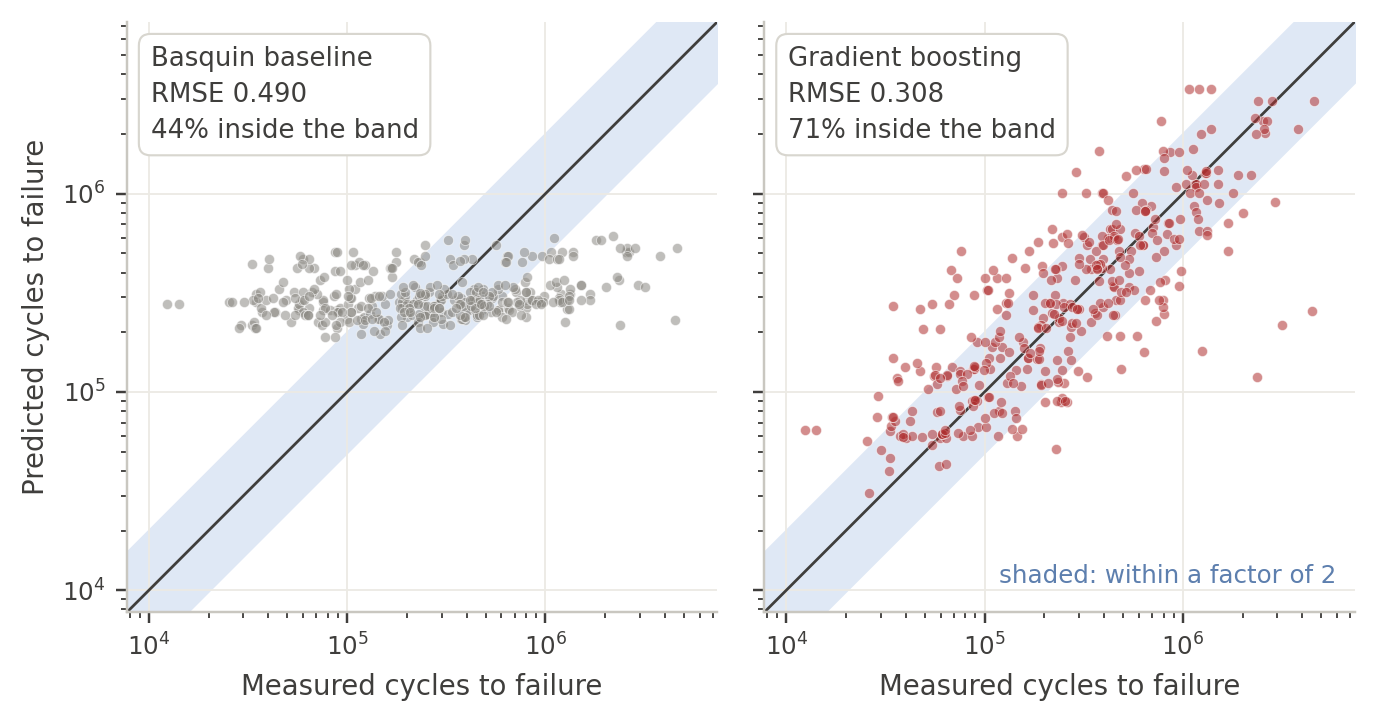

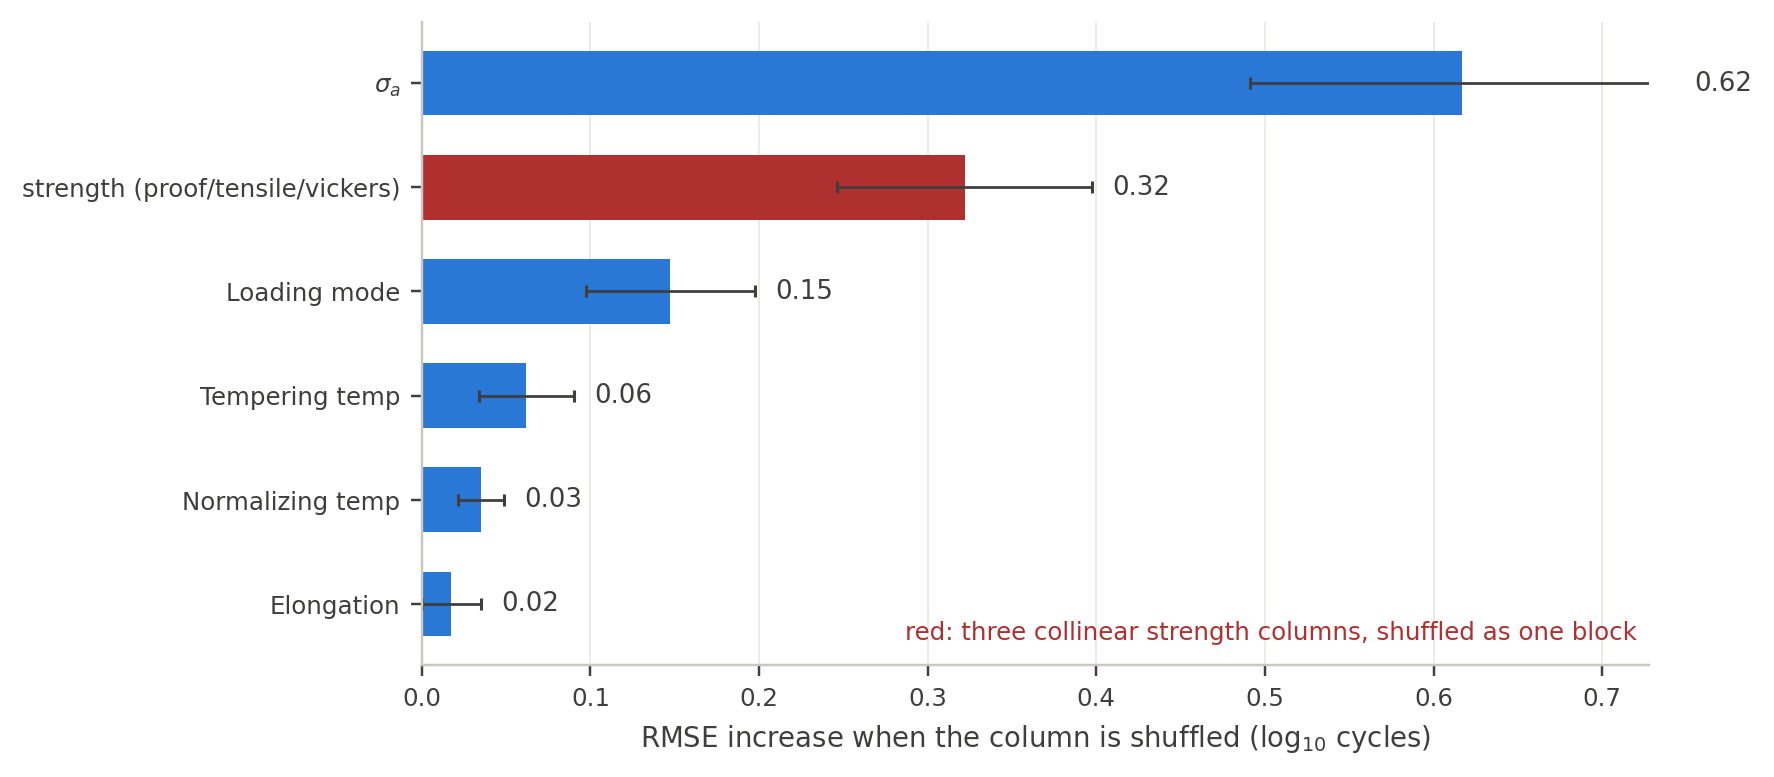

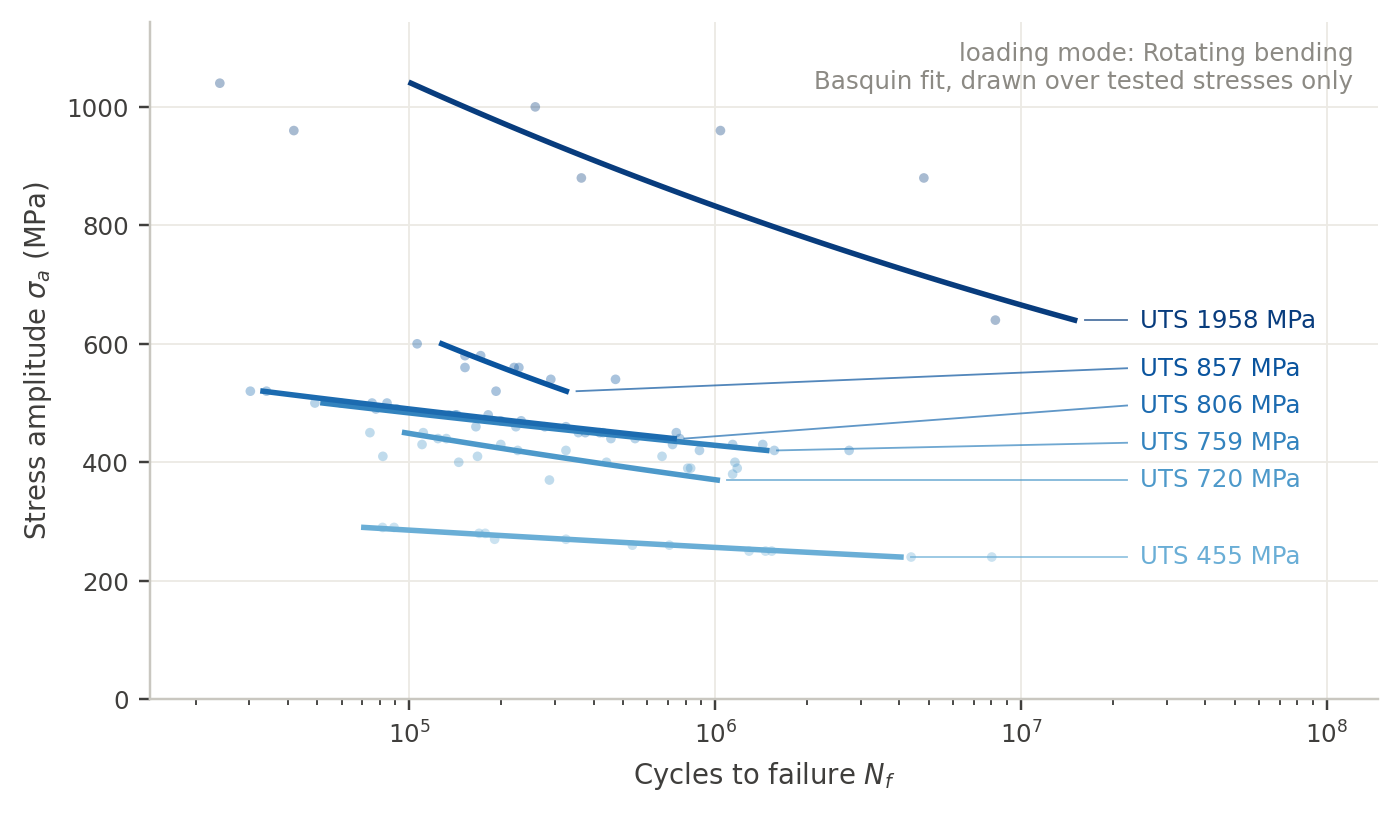

In [33]:
from IPython.display import Image, display
import glob
for f in sorted(glob.glob('figures/[0-9]_*.png')):
    display(Image(f))

## 8. Conclusion

All three machine learning models clearly beat the Basquin baseline. After tuning, HistGradientBoosting has the lowest cross-validation error (RMSE about 0.35), ahead of Random Forest (about 0.37) and Ridge (about 0.40). On unseen test data the chosen model gets RMSE about 0.31, MAE about 0.23 and R² about 0.63. About 71 % of the predictions are within a factor of 2 of the true life. The Basquin baseline has an R² of only about 0.05.

The stress `σa` and the strength of the material are the most important inputs. The error of the best model is not far from the noise floor of about 0.26 given by repeat tests under identical conditions.

The results are weaker than in the reference article, which reports an R² of about 0.73. We believe the difference is partly because the article uses a random split, where rows from the same material state end up in both train and test. Our group split instead measures the ability to generalize to new material states. We have not tested this directly.

Limitations.

- Run-outs are left out, and the residuals suggest some bias at low stress.
- The test set has no S40C and only four S35C rows.
- The 1e7 limit is a simplification.
- Median imputation is fitted on the whole training set before cross-validation, which causes a small leak.
- Differences between the models are small compared with the variation between folds.